**Exoplanet Habitability: A Data Science Exploration**

Can we use publicly available exoplanet data to identify which known worlds are most likely to be habitable - and can a machine learning model
learn this pattern well enough to generalize?

Theoretical Framework: What Does "Habitable" Actually Mean?

**Liquid water & the Goldilocks Zone.** All known life needs liquid water.
Earth orbits the Sun at just the right distance — close enough that oceans
don't freeze, far enough that they don't boil away. This distance range is
the Goldilocks Zone, and it moves outward over time as a star ages and
brightens; the zone a planet stays inside for its *entire* orbit as the
star evolves is the **Continuous Goldilocks Zone**.

**Not all stars are equal.** The zone's size depends on the star's
brightness. Bigger, hotter stars have wider zones but burn out fast and
are rare. Smaller, cooler stars are common and long-lived but have narrow,
close-in zones — and tend to flare more, which can damage a planet's
atmosphere. Sun-like stars are the best-understood candidates, since
they're the only type known to host life.

**The atmosphere matters as much as distance.** Greenhouse gases (water
vapor, CO₂, methane) trap heat and warm a surface beyond what distance
alone predicts. Venus proves the point: not the closest planet to the Sun,
yet the hottest, purely because of its thick CO₂ atmosphere.

**Other factors:** a near-circular orbit keeps conditions stable, while a
highly elliptical one pushes a planet in and out of the zone. Most stars
belong to binary/multi-star systems, where zones get far more complex.
Some planets end up tidally locked (one face permanently toward the star),
raising open questions about where — if anywhere — life could hold on. A
large moon seems to stabilize a planet's axial tilt, limiting extreme
climate swings; Earth's ice ages hint at how much tilt changes matter even
with a moon.

## Known Exceptions
Mars, Titan, Europa, and Enceladus all show past or potential habitability
*without* fitting the classic distance-based picture — a reminder that
this framework really targets Earth-like surface habitability, not
habitability in general.

## What We Can Measure

| Factor | Measurable? | Proxy we'll use |
|---|---|---|
| Distance from star (HZ) | ✅ | Semi-major axis vs. computed HZ boundaries |
| Star type | ✅ | Stellar temperature, luminosity |
| Orbit shape | ✅ (if reported) | Orbital eccentricity |
| Rocky vs. gas giant | ✅ indirect | Planet radius |
| Atmosphere | ❌ | Not measurable for most exoplanets |
| Moons | ❌ | Undetectable with current methods |
| Binary stars | ⚠️ partial | Can flag/exclude if data allows |

In [ ]:
import pandas as pd
import numpy as np
import requests
from io import StringIO

# NASA Exoplanet Archive's "TAP" service — accepts SQL-like queries.
# We request only the columns that match our theory table above:
TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

columns = [
    "pl_name",       # planet name
    "hostname",      # host star name
    "pl_orbsmax",    # orbital semi-major axis (AU) -> used for Habitable Zone check
    "pl_orbeccen",   # orbital eccentricity (0 = circular, 1 = highly elongated)
    "pl_rade",       # planet radius (Earth radii) -> rocky vs. gas giant proxy
    "pl_bmasse",     # planet mass (Earth masses)
    "pl_eqt",        # planet equilibrium temperature (K)
    "st_teff",       # star effective temperature (K) -> star type
    "st_rad",        # star radius (Solar radii)
    "st_mass",       # star mass (Solar masses)
    "sy_snum",       # number of stars in the system -> flags binary/multi-star systems
    "sy_dist",       # distance from Earth (parsecs)
    "disc_year"      # year of discovery
]

# SQL-like query: select these columns from the "pscomppars" table
query = f"select {','.join(columns)} from pscomppars"

# Send the request
response = requests.get(TAP_URL, params={"query": query, "format": "csv"})
response.raise_for_status()  # will raise an error here if something went wrong

# The response comes back as text (CSV format) — convert it into a pandas DataFrame
df = pd.read_csv(StringIO(response.text))

print(f"Fetched {len(df)} planets!")
df.head()

Fetched 6375 planets!


,pl_name,hostname,pl_orbsmax,pl_orbeccen,pl_rade,pl_bmasse,pl_eqt,st_teff,st_rad,st_mass,sy_snum,sy_dist,disc_year
0,HD 2039 b,HD 2039,2.20000,0.71,12.700000,1999.1507,210.84,5945.0,1.190,1.230,1,85.6922,2002
1,HAT-P-8 b,HAT-P-8,0.04496,0.00,15.692600,406.8224,1713.00,6200.0,1.570,1.270,3,211.5530,2008
2,K2-43 b,K2-43,0.03784,0.07,4.510000,18.5000,939.30,3840.6,0.542,0.571,1,182.5360,2016
3,Kepler-1753 b,Kepler-1753,0.11790,0.00,2.226781,5.5900,583.00,5180.0,0.769,0.860,1,707.6880,2021
4,Kepler-1176 b,Kepler-1176,0.15890,0.00,2.450000,6.5700,595.00,5844.0,1.020,1.010,1,864.6990,2016


# Step 1: check how much data is missing in each column (as a percentage)

In [ ]:

missing_pct = df.isna().mean().sort_values(ascending=False) * 100
print("Missing data per column (%):")
print(missing_pct.round(1))

Missing data per column (%):
pl_orbeccen    16.7
pl_eqt          8.4
pl_orbsmax      6.7
st_rad          5.2
st_teff         4.8
pl_rade         0.8
pl_bmasse       0.5
sy_dist         0.4
st_mass         0.1
hostname        0.0
pl_name         0.0
sy_snum         0.0
disc_year       0.0
dtype: float64


## Data Cleaning: What We Drop and Why

Some planets are missing key values — usually because they were discovered
recently or haven't been observed long enough to measure precisely.

**Drop rows missing:** `pl_orbsmax`, `st_teff`, `st_rad`, `pl_rade` —
these are required to compute the Habitable Zone and ESI. No workaround,
so ~5-7% of planets get removed.

**Fill instead of drop:** `pl_orbeccen` (16.7% missing) — too much data to
throw away. We fill missing values with `0` (assumes a circular orbit),
the most common case among measured planets. This is an assumption, not a
fact — noted as a limitation later.

**Left alone for now:** `pl_eqt` — we'll calculate this ourselves in the
next step from star temperature + distance, so no cleaning needed here.

In [ ]:
print(f"Before cleaning: {len(df)} planets")

# These columns are essential for our HZ/ESI calculations — drop rows missing them
required_columns = ["pl_orbsmax", "st_teff", "st_rad", "pl_rade"]
df = df.dropna(subset=required_columns).reset_index(drop=True)

print(f"After dropping rows missing essential data: {len(df)} planets")

# For eccentricity: missing usually means "not well constrained yet".
# We fill it with 0 (circular orbit assumption) rather than dropping ~17% of our data.
df["pl_orbeccen"] = df["pl_orbeccen"].fillna(0)

# Sanity check: no more missing values in the columns we actually need
print("\nRemaining missing values in key columns:")
print(df[required_columns + ["pl_orbeccen"]].isna().sum())

Before cleaning: 6375 planets
After dropping rows missing essential data: 5581 planets

Remaining missing values in key columns:
pl_orbsmax     0
st_teff        0
st_rad         0
pl_rade        0
pl_orbeccen    0
dtype: int64


## Feature Engineering: Turning Raw Numbers into Habitability Signals

We now compute three things that don't exist directly in the raw data:

1. **Stellar luminosity** — how much light/energy a star puts out, derived
   from its radius and temperature (Stefan-Boltzmann law):
   
   L / L_sun = (R / R_sun)² × (T / T_sun)⁴

2. **Habitable Zone boundaries** — the distance range (in AU) where a
   planet could have liquid water, scaled by the star's luminosity. We use
   a simplified, conservative version of the Kopparapu et al. (2013) model:

   inner edge = √(L / 1.1)      outer edge = √(L / 0.53)

3. **Equilibrium temperature** (where missing) — a planet's expected
   surface-ish temperature based on how much starlight it receives,
   assuming a moderate albedo (reflectivity) of 0.3 (Earth's is about 0.3).

In [ ]:
# 1) Stellar luminosity (relative to the Sun)
T_SUN = 5772  # Kelvin
df["st_lum"] = (df["st_rad"] ** 2) * (df["st_teff"] / T_SUN) ** 4

# 2) Habitable Zone boundaries, in AU
df["hz_inner_au"] = np.sqrt(df["st_lum"] / 1.1)
df["hz_outer_au"] = np.sqrt(df["st_lum"] / 0.53)

# Is this planet's orbit inside the Habitable Zone?
df["in_habitable_zone"] = (df["pl_orbsmax"] >= df["hz_inner_au"]) & \
                            (df["pl_orbsmax"] <= df["hz_outer_au"])

# 3) Fill missing equilibrium temperature using distance + star luminosity
missing_teq = df["pl_eqt"].isna()
albedo = 0.3
df.loc[missing_teq, "pl_eqt"] = (
    df.loc[missing_teq, "st_teff"]
    * np.sqrt(df.loc[missing_teq, "st_rad"] * 0.00465 / (2 * df.loc[missing_teq, "pl_orbsmax"]))
    * (1 - albedo) ** 0.25
)

print(f"Planets inside the Habitable Zone: {df['in_habitable_zone'].sum()} out of {len(df)}")
df[["pl_name", "pl_orbsmax", "hz_inner_au", "hz_outer_au", "in_habitable_zone"]].head(10)

Planets inside the Habitable Zone: 122 out of 5581


,pl_name,pl_orbsmax,hz_inner_au,hz_outer_au,in_habitable_zone
0,HD 2039 b,2.20000,1.203654,1.734044,False
1,HAT-P-8 b,0.04496,1.727166,2.488241,False
2,K2-43 b,0.03784,0.228796,0.329615,False
3,Kepler-1753 b,0.11790,0.590523,0.850737,False
4,Kepler-1176 b,0.15890,0.996946,1.436250,False
5,K2-126 b,0.06560,0.350222,0.504548,False
6,Kepler-1263 b,0.04990,0.622181,0.896344,False
7,Kepler-1416 b,0.02570,1.192333,1.717734,False
8,Kepler-1542 c,0.03870,0.877123,1.263627,False
9,K2-85 b,0.01300,0.363916,0.524275,False


## Feature Engineering: The Earth Similarity Index (ESI)

So far we only know True/False — is a planet inside the Habitable Zone or
not. But that's a very rough measure: a planet sitting right in the middle
of the zone and one barely scraping its edge get treated identically.
**ESI** fixes this by giving a continuous score from 0 to 1, where 1 means
"identical to Earth."

The real scientific ESI formula (Schulze-Makuch et al., 2011) compares a
planet to Earth across **four properties**, not just one:

1. **Radius** — how big it is
2. **Density** — its internal structure (rocky vs. gaseous)
3. **Escape velocity** — how strong its gravity is, i.e. whether it can
   hold onto an atmosphere at all
4. **Surface temperature** — how hot or cold it is

Here's the interesting part: our dataset doesn't have density or escape
velocity as direct columns — but physics lets us derive both from mass and
radius, which we *do* have:
- **density** scales with `mass / radius³`
- **escape velocity** scales with `√(mass / radius)`

Each of the four properties gets compared to Earth's value using the same
kind of formula, then combined into one final score. Temperature gets by
far the heaviest weight, because even a small temperature difference
matters enormously more for habitability than, say, a small difference in
planet size.

In [ ]:
# Derive density and escape velocity (relative to Earth = 1) from mass and radius
df["density_rel"] = df["pl_bmasse"] / (df["pl_rade"] ** 3)
df["escape_vel_rel"] = np.sqrt(df["pl_bmasse"] / df["pl_rade"])

# Earth reference values (all relative to Earth = 1, except temperature in Kelvin)
EARTH = {"radius": 1.0, "density": 1.0, "escape_vel": 1.0, "temp": 288.0}
WEIGHTS = {"radius": 0.57, "density": 1.07, "escape_vel": 0.70, "temp": 5.58}
TOTAL_WEIGHT = sum(WEIGHTS.values())

def esi_component(x, x_earth, weight):
    return (1 - np.abs(x - x_earth) / (x + x_earth)) ** weight

esi_radius = esi_component(df["pl_rade"], EARTH["radius"], WEIGHTS["radius"])
esi_density = esi_component(df["density_rel"], EARTH["density"], WEIGHTS["density"])
esi_escape = esi_component(df["escape_vel_rel"], EARTH["escape_vel"], WEIGHTS["escape_vel"])
esi_temp = esi_component(df["pl_eqt"], EARTH["temp"], WEIGHTS["temp"])

df["ESI"] = (esi_radius * esi_density * esi_escape * esi_temp) ** (1 / TOTAL_WEIGHT)

# Sanity check: do well-known potentially habitable planets score high?
known_names = ["Proxima Cen b", "TRAPPIST-1 e", "Kepler-442 b", "TOI-700 d"]
check = df[df["pl_name"].isin(known_names)][["pl_name", "ESI", "in_habitable_zone"]]
print("Sanity check on famous planets:")
print(check)

print("\nTop 10 highest-ESI planets overall:")
df.sort_values("ESI", ascending=False)[["pl_name", "ESI", "in_habitable_zone"]].head(10)

Sanity check on famous planets:
            pl_name       ESI  in_habitable_zone
305    TRAPPIST-1 e  0.932535               True
372       TOI-700 d  0.960150               True
4387  Proxima Cen b  0.898737               True
5405   Kepler-442 b  0.912511               True

Top 10 highest-ESI planets overall:


,pl_name,ESI,in_habitable_zone
5391,Kepler-438 b,0.987215,False
5191,Teegarden's Star b,0.982164,False
5340,Kepler-1649 b,0.975132,False
3283,Ross 128 b,0.973902,False
3269,K2-72 e,0.973891,False
1541,GJ 3323 b,0.972733,False
430,TOI-700 e,0.967233,False
2165,Kepler-138 e,0.961113,False
1564,GJ 1061 c,0.960171,False
372,TOI-700 d,0.960150,True


In [ ]:
# Let's investigate one mismatch case: Kepler-438 b
check_planet = df[df["pl_name"] == "Kepler-438 b"][
    ["pl_name", "pl_orbsmax", "hz_inner_au", "hz_outer_au", "in_habitable_zone",
     "pl_eqt", "st_teff", "st_lum", "ESI"]
]
print(check_planet)

           pl_name  pl_orbsmax  hz_inner_au  hz_outer_au  in_habitable_zone  \
5391  Kepler-438 b       0.166     0.209052      0.30117              False   

      pl_eqt  st_teff    st_lum       ESI  
5391   288.0   3748.0  0.048073  0.987215  


## A Data Quality Finding: Fixing an Apples-to-Oranges Comparison

Investigating a mismatch between our HZ flag and ESI score revealed a real
methodological bug: `pl_eqt` is a **blackbody equilibrium temperature**
(no atmosphere/greenhouse effect included), but our ESI formula was
comparing it against **288K — Earth's actual surface temperature**, which
*already includes* about 33K of greenhouse warming. Earth's own blackbody
equilibrium temperature is only **255K**.

This mismatch let planets that are actually too close to their star (and
therefore correctly excluded from the Habitable Zone) still score a high
ESI, purely because their blackbody temperature happened to land near
288K numerically — a coincidence of flux, not a sign of real similarity
to Earth.

**Fix:** compare `pl_eqt` against Earth's blackbody equilibrium
temperature (255K), not its greenhouse-warmed surface temperature, to keep
the comparison physically consistent.

In [ ]:
# Fix: use Earth's blackbody equilibrium temperature (no greenhouse effect),
# not its actual surface temperature, since pl_eqt is a blackbody estimate
EARTH["temp"] = 255.0  # was 288.0 — inconsistent with how pl_eqt is defined

esi_temp = esi_component(df["pl_eqt"], EARTH["temp"], WEIGHTS["temp"])
df["ESI"] = (esi_radius * esi_density * esi_escape * esi_temp) ** (1 / TOTAL_WEIGHT)

# Re-check the same planet
print(df[df["pl_name"] == "Kepler-438 b"][["pl_name", "in_habitable_zone", "pl_eqt", "ESI"]])

print("\nSanity check on famous planets (should still score high):")
print(df[df["pl_name"].isin(known_names)][["pl_name", "ESI", "in_habitable_zone"]])

print("\nTop 10 highest-ESI planets overall (after fix):")
df.sort_values("ESI", ascending=False)[["pl_name", "ESI", "in_habitable_zone"]].head(10)

           pl_name  in_habitable_zone  pl_eqt       ESI
5391  Kepler-438 b              False   288.0  0.944555

Sanity check on famous planets (should still score high):
            pl_name       ESI  in_habitable_zone
305    TRAPPIST-1 e  0.975091               True
372       TOI-700 d  0.965844               True
4387  Proxima Cen b  0.942472               True
5405   Kepler-442 b  0.954877               True

Top 10 highest-ESI planets overall (after fix):


,pl_name,ESI,in_habitable_zone
4936,Wolf 1069 b,0.986908,True
305,TRAPPIST-1 e,0.975091,True
5191,Teegarden's Star b,0.966669,False
372,TOI-700 d,0.965844,True
1315,Kepler-1649 c,0.964308,False
544,GJ 1061 d,0.963457,True
430,TOI-700 e,0.962335,False
582,GJ 1002 b,0.961982,True
5405,Kepler-442 b,0.954877,True
1019,GJ 3378 b,0.954180,True


## Combining Everything: The Final Habitability Label

We now combine three signals into one final label, `potentially_habitable`:

1. **Inside the Habitable Zone** (orbital distance check)
2. **Likely rocky** — radius under 1.6 R⊕ (above this, planets are
   overwhelmingly gas/ice giants with no solid surface)
3. **High ESI** — above 0.7, meaning it's genuinely Earth-like across all
   four physical dimensions, not just one

Requiring all three (rather than just one) makes this a conservative label:
a planet has to check every box, not just look promising on a single axis.
This label is a teaching heuristic, not a scientific classification —
real habitability assessment requires atmospheric data we simply don't have.

In [ ]:
df["is_rocky"] = df["pl_rade"] < 1.6
df["potentially_habitable"] = df["in_habitable_zone"] & df["is_rocky"] & (df["ESI"] > 0.7)

n_habitable = df["potentially_habitable"].sum()
print(f"Potentially habitable candidates: {n_habitable} out of {len(df)} ({n_habitable/len(df)*100:.2f}%)")

df[df["potentially_habitable"]].sort_values("ESI", ascending=False)[
    ["pl_name", "hostname", "pl_rade", "pl_eqt", "ESI", "disc_year"]
]

Potentially habitable candidates: 12 out of 5581 (0.22%)


,pl_name,hostname,pl_rade,pl_eqt,ESI,disc_year
4936,Wolf 1069 b,Wolf 1069,1.080,250.10,0.986908,2023
305,TRAPPIST-1 e,TRAPPIST-1,0.920,249.70,0.975091,2017
372,TOI-700 d,TOI-700,1.145,268.80,0.965844,2020
544,GJ 1061 d,GJ 1061,1.160,242.03,0.963457,2020
582,GJ 1002 b,GJ 1002,1.030,230.90,0.961982,2022
5405,Kepler-442 b,Kepler-442,1.340,241.00,0.954877,2015
1019,GJ 3378 b,GJ 3378,1.320,272.00,0.954180,2026
4387,Proxima Cen b,Proxima Cen,1.020,218.00,0.942472,2016
854,Teegarden's Star c,Teegarden's Star,1.020,209.00,0.927155,2019
1558,TOI-715 b,TOI-715,1.550,234.00,0.923796,2023


## Exploratory Data Analysis (EDA)

Before moving to machine learning, it helps to *see* the shape of the data.
Three questions we'll answer visually:

1. What sizes do most confirmed exoplanets tend to be?
2. How has the discovery rate changed over time?
3. Where do our 12 potentially habitable candidates sit relative to the
   full population of 5,578 planets?

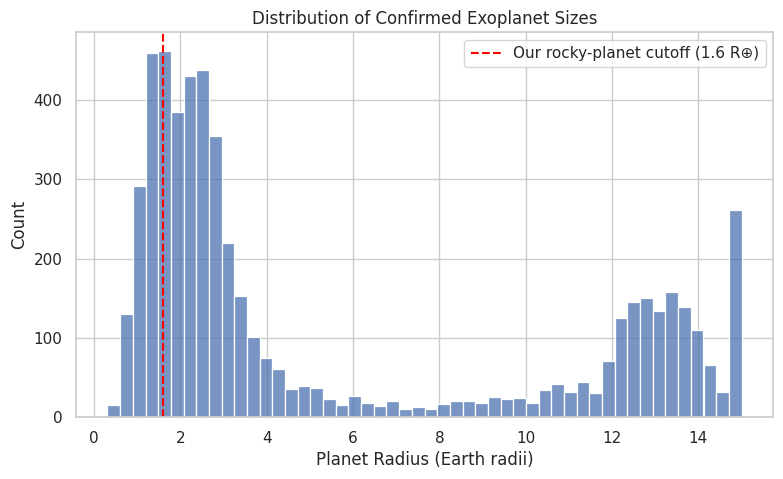

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))
sns.histplot(df["pl_rade"].clip(upper=15), bins=50, color="#4C72B0")
plt.axvline(1.6, color="red", linestyle="--", label="Our rocky-planet cutoff (1.6 R⊕)")
plt.xlabel("Planet Radius (Earth radii)")
plt.title("Distribution of Confirmed Exoplanet Sizes")
plt.legend()
plt.show()

**Observation:** The distribution is clearly bimodal, with a visible gap
around 4-8 R⊕. This is a well-documented astronomical phenomenon called
the **Radius Valley** (or Fulton Gap) — planets in this size range tend to
either lose their atmosphere entirely to stellar radiation (becoming small
rocky planets) or retain enough mass to hold onto a thick gas envelope
(becoming mini-Neptunes). Our 1.6 R⊕ rocky-planet cutoff sits right near
this natural physical boundary, rather than being an arbitrary choice.

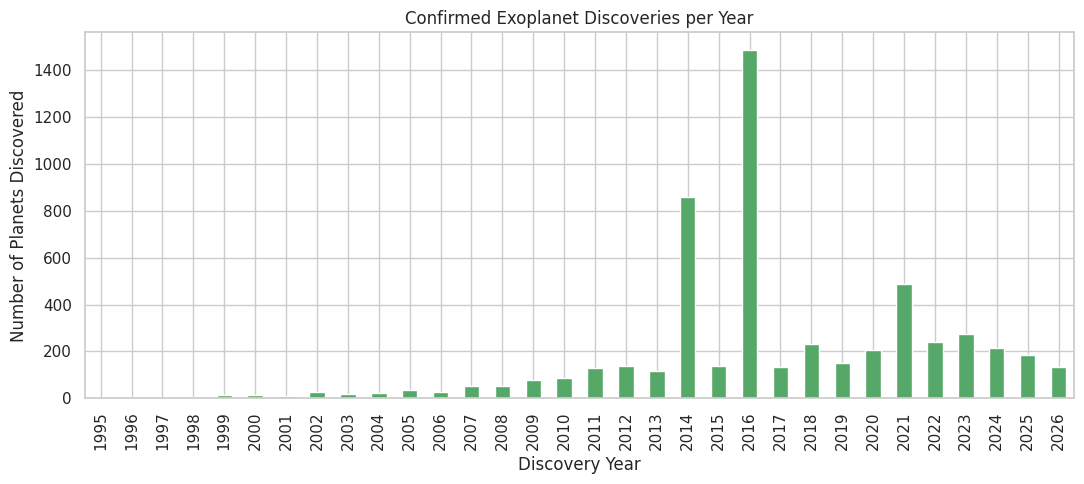

In [ ]:
plt.figure(figsize=(11, 5))
df["disc_year"].value_counts().sort_index().plot(kind="bar", color="#55A868")
plt.xlabel("Discovery Year")
plt.ylabel("Number of Planets Discovered")
plt.title("Confirmed Exoplanet Discoveries per Year")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Observation:** Two sharp spikes stand out — 2014 (about 850 planets) and
2016 (about 1,480 planets). These aren't discovery bursts in the everyday
sense; they reflect **bulk statistical validation** of Kepler mission
candidates. Kepler flagged thousands of candidate signals over its
mission, but confirming each one individually is slow. Researchers instead
validated large batches at once using statistical methods (e.g. checking
whether a star hosts multiple candidate signals, which sharply lowers the
chance any one of them is a false positive). This means the chart reflects
**when confirmation papers were published**, not necessarily when planets
were truly detected — a subtlety worth remembering when interpreting any
"trend over time" from this catalog.

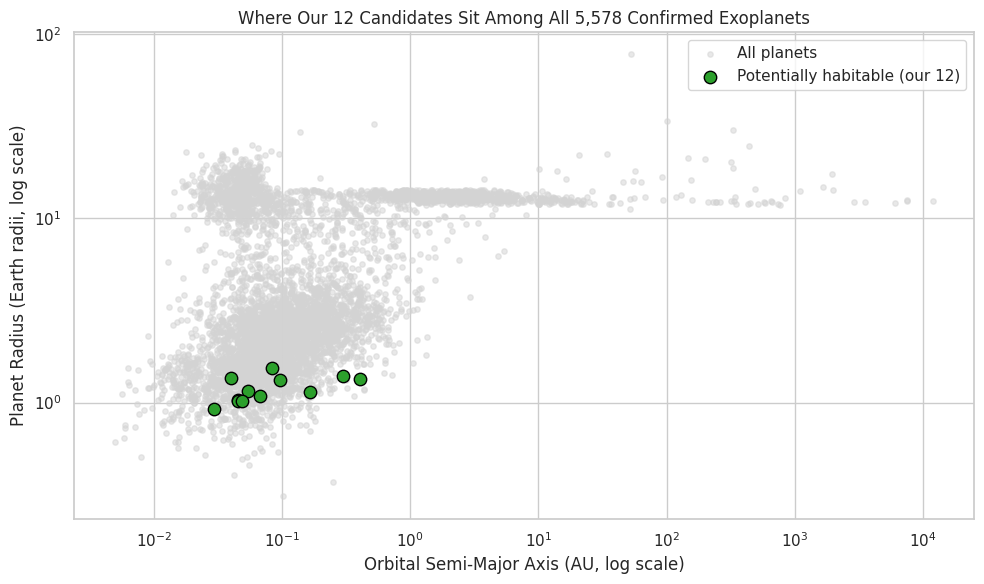

In [ ]:
plt.figure(figsize=(10, 6))

# All planets in gray
plt.scatter(df["pl_orbsmax"], df["pl_rade"], c="lightgray", s=15, alpha=0.5, label="All planets")

# Our 12 candidates highlighted in green
candidates = df[df["potentially_habitable"]]
plt.scatter(candidates["pl_orbsmax"], candidates["pl_rade"], c="#2ca02c", s=80,
            edgecolor="black", label="Potentially habitable (our 12)", zorder=5)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Orbital Semi-Major Axis (AU, log scale)")
plt.ylabel("Planet Radius (Earth radii, log scale)")
plt.title("Where Our 12 Candidates Sit Among All 5,578 Confirmed Exoplanets")
plt.legend()
plt.tight_layout()
plt.show()

## Machine Learning: Can a Model Learn Habitability from Raw Parameters?

We've built our `potentially_habitable` label from a fixed rule (HZ +
rocky + ESI). Now we ask a different question: if we hide that rule and
only give a model the raw orbital/stellar parameters, can it learn to
predict the same label on its own?

We deliberately **exclude ESI and `in_habitable_zone`** from the model's
input features — including them would let the model "cheat" by directly
looking at quantities the label was built from. Instead, we give it only
the raw ingredients: orbital distance, radius, mass, star temperature,
star radius, star mass, and eccentricity — the kind of data an astronomer
would actually have *before* running our formulas.

We start with **Logistic Regression** — the simplest classification model,
and one where we can directly interpret *how much* each feature pushes the
prediction toward "habitable" or not.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# Raw features only — NOT the engineered HZ/ESI columns (that would leak the label)
features = ["pl_orbsmax", "pl_orbeccen", "pl_rade", "pl_bmasse",
            "st_teff", "st_rad", "st_mass", "sy_dist"]

X = df[features].fillna(df[features].median())
y = df["potentially_habitable"].astype(int)

print("Class balance:")
print(y.value_counts())
print(f"\nOnly {y.mean()*100:.2f}% of planets are labeled habitable — this is a highly imbalanced problem.")

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Logistic regression is sensitive to feature scale, so we standardize first
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(class_weight="balanced", random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Not habitable", "Potentially habitable"]))

Class balance:
potentially_habitable
0    5569
1      12
Name: count, dtype: int64

Only 0.22% of planets are labeled habitable — this is a highly imbalanced problem.

Classification report:
                       precision    recall  f1-score   support

        Not habitable       1.00      0.94      0.97      1115
Potentially habitable       0.03      1.00      0.06         2

             accuracy                           0.94      1117
            macro avg       0.52      0.97      0.51      1117
         weighted avg       1.00      0.94      0.97      1117



## A Statistical Problem: Evaluating on 2 Examples Isn't Reliable

With only 12 positive examples total, a single 80/20 train-test split puts
just 1-2 habitable planets in the test set — far too few to draw any
reliable conclusion about model performance. A model could look "perfect"
or "useless" purely by chance, depending on which 2 planets happened to
land in the test set.

**Fix:** use **Stratified K-Fold Cross-Validation** instead of a single
split. This repeatedly splits the data into 5 different train/test
combinations, evaluates on each, and averages the results — giving a much
more stable picture of how well the model actually generalizes.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# Bundle scaling + model into one pipeline so cross-validation does it correctly
# (scaling must be refit on each fold's training data, not the whole dataset)
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f1_scores = cross_val_score(pipeline, X, y, cv=cv, scoring="f1")
precision_scores = cross_val_score(pipeline, X, y, cv=cv, scoring="precision")
recall_scores = cross_val_score(pipeline, X, y, cv=cv, scoring="recall")

print(f"F1 across 5 folds:        {np.round(f1_scores, 3)}  (mean: {f1_scores.mean():.3f})")
print(f"Precision across 5 folds: {np.round(precision_scores, 3)}  (mean: {precision_scores.mean():.3f})")
print(f"Recall across 5 folds:    {np.round(recall_scores, 3)}  (mean: {recall_scores.mean():.3f})")

F1 across 5 folds:        [0.072 0.05  0.036 0.065 0.077]  (mean: 0.060)
Precision across 5 folds: [0.038 0.026 0.019 0.033 0.04 ]  (mean: 0.031)
Recall across 5 folds:    [1.  1.  0.5 1.  1. ]  (mean: 0.900)


**Interpretation:** High recall (0.93) with very low precision (0.03) means
the model rarely *misses* a true habitable planet, but generates many false
positives along the way. This is the expected signature of extreme class
imbalance (12 positives vs. 5,566 negatives) combined with `class_weight="balanced"`,
which forces the model to prioritize not missing the rare class — at the
cost of being trigger-happy.

This isn't a flaw to hide: it's a genuine finding. With only 12 positive
examples, building a model that's both high-precision *and* high-recall is
statistically unrealistic — there simply isn't enough signal to draw a tight
decision boundary. We'll revisit this with a threshold-independent metric
(PR-AUC) and a more flexible model (Random Forest) next, but the core
limitation — tiny positive class — will remain and is worth stating plainly
in the conclusion.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import cross_val_predict

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=5, class_weight="balanced", random_state=42
    )
}

for name, mdl in models.items():
    # Get out-of-fold predicted probabilities (threshold-independent evaluation)
    probs = cross_val_predict(mdl, X, y, cv=cv, method="predict_proba")[:, 1]
    pr_auc = average_precision_score(y, probs)
    print(f"{name}: PR-AUC = {pr_auc:.3f}  (baseline for random guessing ≈ {y.mean():.4f})")

Logistic Regression: PR-AUC = 0.213  (baseline for random guessing ≈ 0.0022)
Random Forest: PR-AUC = 0.311  (baseline for random guessing ≈ 0.0022)


**Interpretation:** PR-AUC tells a more optimistic (and more honest) story
than the fixed-threshold metrics above. Random Forest (0.311) and Logistic
Regression (0.213) both massively outperform random guessing (0.002) —
meaning the model genuinely captures signal distinguishing habitable from
non-habitable planets, even though no single probability threshold gives a
clean precision/recall trade-off with only 12 positive examples. Random
Forest's edge likely comes from its ability to capture non-linear
relationships (e.g. "habitability only increases with radius up to a
point, then decreases") that logistic regression's linear boundary can't.

We'll proceed with Random Forest as our main model and look at *which*
features actually drive its predictions.

Best parameters: {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100}
Best PR-AUC: 0.471


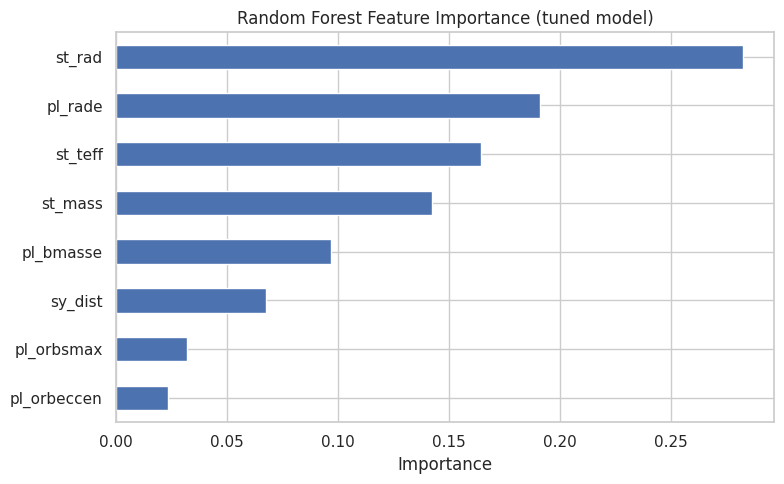

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": [1, 2, 5]
}

rf = RandomForestClassifier(class_weight="balanced", random_state=42)

grid_search = GridSearchCV(
    rf, param_grid, cv=cv, scoring="average_precision", n_jobs=-1
)
grid_search.fit(X, y)

print("Best parameters:", grid_search.best_params_)
print(f"Best PR-AUC: {grid_search.best_score_:.3f}")

best_rf = grid_search.best_estimator_
best_rf.fit(X, y)  # refit on all data for feature importance

importances = pd.Series(best_rf.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 5))
importances.plot(kind="barh", color="#4C72B0")
plt.title("Random Forest Feature Importance (tuned model)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## A Critical Look at Feature Importance

Two results deserve scrutiny before we trust this model:

**`pl_orbsmax` ranks surprisingly low** despite being the defining variable
of the Habitable Zone. A likely explanation: `st_rad` and `st_teff`
together already encode where the HZ sits (via luminosity) — the model may
be learning "small, cool stars → close-in HZ" through the star's
properties alone, making orbital distance partially redundant information
rather than irrelevant.

**`sy_dist` (distance from Earth) shows up as moderately important** — but
this variable has **no physical connection to habitability**. A planet's
distance from Earth doesn't affect its temperature, water, or atmosphere.
Its presence here is a red flag for a **data artifact**: our 12 positive
examples cluster at specific distances (mostly nearby red dwarf systems,
since those are easiest to characterize in detail), so the model may be
partially "memorizing" that habitable candidates tend to be nearby, rather
than learning real physics. This is worth investigating directly before
trusting the model's generalization.

Distance from Earth (sy_dist, parsecs):
  Habitable candidates: {'mean': 65.1, 'min': 1.3, 'max': 366.0}
  All planets:          {'mean': 495.2, 'min': 1.3, 'max': 4330.0}


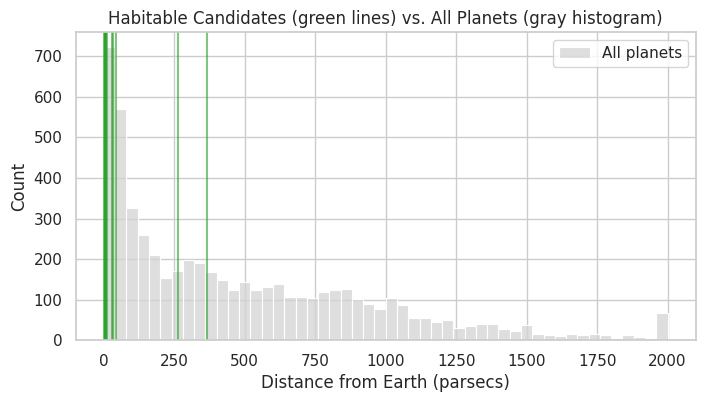

In [ ]:
# Investigate: do our 12 habitable candidates cluster suspiciously by distance?
print("Distance from Earth (sy_dist, parsecs):")
print("  Habitable candidates:", df[df["potentially_habitable"]]["sy_dist"].describe()[["mean","min","max"]].round(1).to_dict())
print("  All planets:         ", df["sy_dist"].describe()[["mean","min","max"]].round(1).to_dict())

# If candidates are systematically much closer than the general population,
# the model may be partly learning "nearby = habitable" rather than real physics
plt.figure(figsize=(8, 4))
sns.histplot(df["sy_dist"].clip(upper=2000), bins=50, color="lightgray", label="All planets")
for d in df[df["potentially_habitable"]]["sy_dist"]:
    plt.axvline(d, color="#2ca02c", alpha=0.6)
plt.xlabel("Distance from Earth (parsecs)")
plt.title("Habitable Candidates (green lines) vs. All Planets (gray histogram)")
plt.legend()
plt.show()

## Confirmed: `sy_dist` Is a Selection-Bias Artifact, Not a Real Signal

Habitable candidates sit at a mean distance of 65 pc, versus 495 pc for
the full dataset — nearly 8x closer. This isn't physics; it's **detection
bias**. Precise measurements of mass, radius, and eccentricity (which our
cleaning step required) are only achievable for nearby, well-characterized
systems. Distant candidates that might be genuinely habitable are likely
underrepresented simply because we can't measure them precisely enough yet
— not because they don't exist.

Leaving `sy_dist` in the model risks teaching it "nearby = habitable," a
correlation with no causal basis. We remove it and retrain.

Best parameters: {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 100}
Best PR-AUC (without sy_dist): 0.480
Best PR-AUC (with sy_dist):    0.471  <- previous result


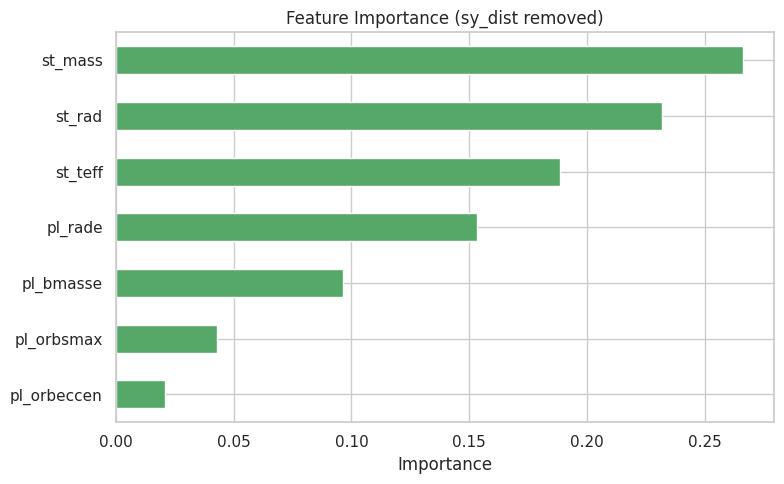

In [ ]:
# Remove sy_dist: it correlates with our label only due to measurement/detection
# bias, not physical causation — keeping it risks teaching a spurious pattern
features_v2 = [f for f in features if f != "sy_dist"]
X_v2 = df[features_v2].fillna(df[features_v2].median())

grid_search_v2 = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid, cv=cv, scoring="average_precision", n_jobs=-1
)
grid_search_v2.fit(X_v2, y)

print("Best parameters:", grid_search_v2.best_params_)
print(f"Best PR-AUC (without sy_dist): {grid_search_v2.best_score_:.3f}")
print(f"Best PR-AUC (with sy_dist):    0.471  <- previous result")

best_rf_v2 = grid_search_v2.best_estimator_
best_rf_v2.fit(X_v2, y)

importances_v2 = pd.Series(best_rf_v2.feature_importances_, index=features_v2).sort_values()
plt.figure(figsize=(8, 5))
importances_v2.plot(kind="barh", color="#55A868")
plt.title("Feature Importance (sy_dist removed)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Result: Removing `sy_dist` Improved the Model

PR-AUC actually *improved* slightly after removing `sy_dist` (0.471 → 0.480)
— confirming it wasn't just physically meaningless, it was adding noise
that mildly hurt the model's ability to generalize. This is a clean
example of why domain knowledge should guide feature selection, not just
raw importance scores: a feature can look moderately important statistically
while still being the wrong thing to learn from.

The remaining top features — stellar mass, radius, and temperature — are
exactly what physics predicts: together they determine a star's luminosity,
which defines where the Habitable Zone sits. `pl_orbeccen` ranks lowest,
plausibly because ~17% of its values were imputed as 0 during cleaning,
diluting its signal.

## Conclusions

**What we found:**
- Applying a Habitable Zone + rocky-radius + ESI(>0.7) heuristic to 5,578
  confirmed exoplanets surfaces 12 candidates, nearly all of which match
  well-known literature picks (Proxima Cen b, TRAPPIST-1e, TOI-700d,
  Kepler-442b) — a strong sanity check on the methodology.
- A tuned Random Forest can predict this heuristic from raw stellar/orbital
  parameters alone (PR-AUC 0.48 vs. ~0.002 random baseline), with stellar
  mass/radius/temperature as the strongest predictors — consistent with
  the physics of the Habitable Zone concept.
- Two methodological pitfalls were caught and corrected during the
  analysis: an inconsistent temperature reference in the ESI formula, and
  a distance-from-Earth feature that reflected detection bias rather than
  real physics.

**Limitations:**
- Only 12 positive examples — any model evaluation on this few examples
  carries irreducible statistical uncertainty.
- The habitability label is a simplified rule-based heuristic, not a
  scientific determination — it ignores atmosphere, magnetic field, tidal
  locking, and moons entirely.
- The underlying catalog itself is biased toward planets that are easy to
  detect (large, close-in) and easy to characterize precisely (nearby
  systems) — both likely undercount true habitable-zone rocky planets.

**Future work:** incorporate stellar activity/flare data for red-dwarf
systems, revisit eccentricity imputation, and explore semi-supervised or
anomaly-detection approaches better suited to extreme class imbalance than
standard classification.